# Dashboard Visualisasi StyleGAN3-T — Skripsi
**Pelatihan penuh 3000 Kimg | 11 Tahap | Kaggle T4 x2 GPU**

Notebook ini memvisualisasikan seluruh perjalanan pelatihan StyleGAN3 dari Kimg 0 hingga 3000.
Jalankan semua sel dari atas ke bawah dengan **Run All**.

In [1]:
import os, glob, json, re, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.image as mpimg
import seaborn as sns

# Tema gelap profesional
PALETTE = {'fid':'#2ecc71','aug':'#9b59b6','speed':'#e67e22',
           'vram':'#e74c3c','ram':'#3498db','accent':'#f39c12'}
BG, CARD, TXT, GRID = '#0f1117', '#1a1d27', '#e8eaf0', '#2a2d3e'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':CARD,'axes.edgecolor':GRID,
    'grid.color':GRID,'text.color':TXT,'axes.labelcolor':TXT,
    'xtick.color':TXT,'ytick.color':TXT,'legend.facecolor':CARD,
    'legend.edgecolor':GRID,'font.family':'DejaVu Sans','figure.dpi':110
})

BASE = r'c:\new era code\GAN_Kompre\Workspace_StyleGAN3\output stylegan3'
kimg_start = {1:0,2:300,3:600,4:900,5:1200,6:1300,7:1600,8:1900,9:2200,10:2500,11:2800}
print('Setup selesai. Folder:', len(glob.glob(os.path.join(BASE,'tahap *'))))


Setup selesai. Folder: 15


In [2]:
def parse_plain(line):
    d = {}
    for k,p in [('kimg',r'kimg\s+([\d\.]+)'),('sec',r'sec/kimg\s+([\d\.]+)'),
                ('aug',r'augment\s+([\d\.]+)'),('cpu',r'cpumem\s+([\d\.]+)'),
                ('gpu',r'gpumem\s+([\d\.]+)')]:
        m = re.search(p, line)
        if m: d[k] = float(m.group(1))
    return d if 'kimg' in d else None

log_rows, fid_rows = [], []
for tahap_dir in sorted(glob.glob(os.path.join(BASE,'tahap *'))):
    t = int(os.path.basename(tahap_dir).split()[-1])
    offset = kimg_start.get(t, (t-1)*300)
    lf = os.path.join(tahap_dir,'log.txt')
    ff = os.path.join(tahap_dir,'metric-fid50k_full.jsonl')
    if os.path.exists(lf):
        with open(lf) as f:
            for raw in f:
                d = parse_plain(raw.strip())
                if d:
                    log_rows.append(dict(Tahap=t,Kimg=d['kimg']+offset,
                        Sec=d.get('sec',0),Aug=d.get('aug',0),
                        CPU=d.get('cpu',0),GPU=d.get('gpu',0)))
    if os.path.exists(ff):
        with open(ff) as f:
            for line in f:
                line = line.strip()
                if not line: continue
                d = json.loads(line)
                pkl = os.path.basename(d.get('snapshot_pkl',''))
                try: local_k = int(pkl.replace('network-snapshot-','').replace('.pkl',''))
                except: continue
                fid_rows.append(dict(Kimg=offset+local_k,FID=d['results']['fid50k_full'],Tahap=t))

df  = pd.DataFrame(log_rows).sort_values('Kimg').reset_index(drop=True)
dff = pd.DataFrame(fid_rows).sort_values('Kimg').drop_duplicates('Kimg').reset_index(drop=True)
best_idx = dff.FID.idxmin()
bk, bf = dff.loc[best_idx,'Kimg'], dff.loc[best_idx,'FID']
print(f'Log entries : {len(df)} | Kimg: {df.Kimg.min():.0f} - {df.Kimg.max():.0f}')
print(f'FID entries : {len(dff)}')
print(f'Best FID    : {bf:.2f} @ Kimg {bk:.0f}')
print(f'FID Akhir   : {dff.FID.iloc[-1]:.2f}')


Log entries : 772 | Kimg: 0 - 3000
FID entries : 31
Best FID    : 62.66 @ Kimg 2000
FID Akhir   : 65.63


---
## 📈 Visualisasi 1 — Kurva FID Score (Full 3000 Kimg)

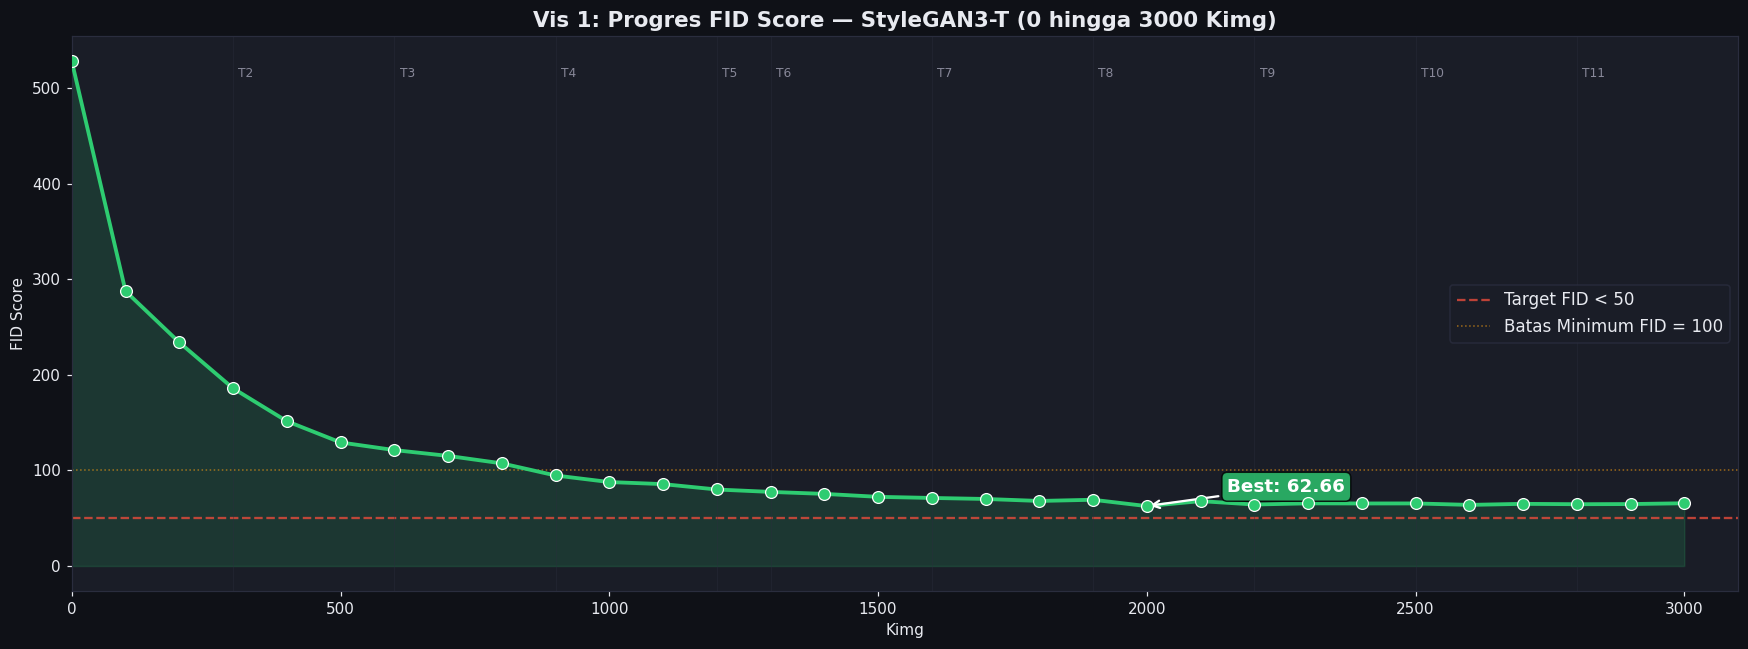

In [3]:
# VISUALISASI 1: Kurva FID Score (Full 3000 Kimg)
fig, ax = plt.subplots(figsize=(16,6))
ax.fill_between(dff.Kimg, dff.FID, alpha=0.15, color=PALETTE['fid'])
ax.plot(dff.Kimg, dff.FID, color=PALETTE['fid'], lw=2.5, zorder=3)
ax.scatter(dff.Kimg, dff.FID, color=PALETTE['fid'], s=60, zorder=4, edgecolors='white', lw=0.8)
ax.axhline(50,  color='#e74c3c', lw=1.5, linestyle='--', alpha=0.8, label='Target FID < 50')
ax.axhline(100, color=PALETTE['accent'], lw=1, linestyle=':', alpha=0.6, label='Batas Minimum FID = 100')
ax.annotate(f'Best: {bf:.2f}', xy=(bk,bf), xytext=(bk+150,bf+15),
    color='white', fontsize=12, fontweight='bold',
    arrowprops=dict(arrowstyle='->',color='white',lw=1.5),
    bbox=dict(boxstyle='round,pad=0.3',facecolor=PALETTE['fid'],alpha=0.8))
for t,start in sorted(kimg_start.items()):
    ax.axvline(start, color=GRID, lw=0.5, alpha=0.5)
    if start > 0: ax.text(start+10, dff.FID.max()*0.97, f'T{t}', color='#888899', fontsize=8)
ax.set_title('Vis 1: Progres FID Score — StyleGAN3-T (0 hingga 3000 Kimg)', fontsize=14, fontweight='bold')
ax.set_xlabel('Kimg'); ax.set_ylabel('FID Score')
ax.legend(fontsize=11); ax.set_xlim(0,3100)
plt.tight_layout(); plt.show()


---
## 📊 Visualisasi 2 — FID Akhir per Tahap

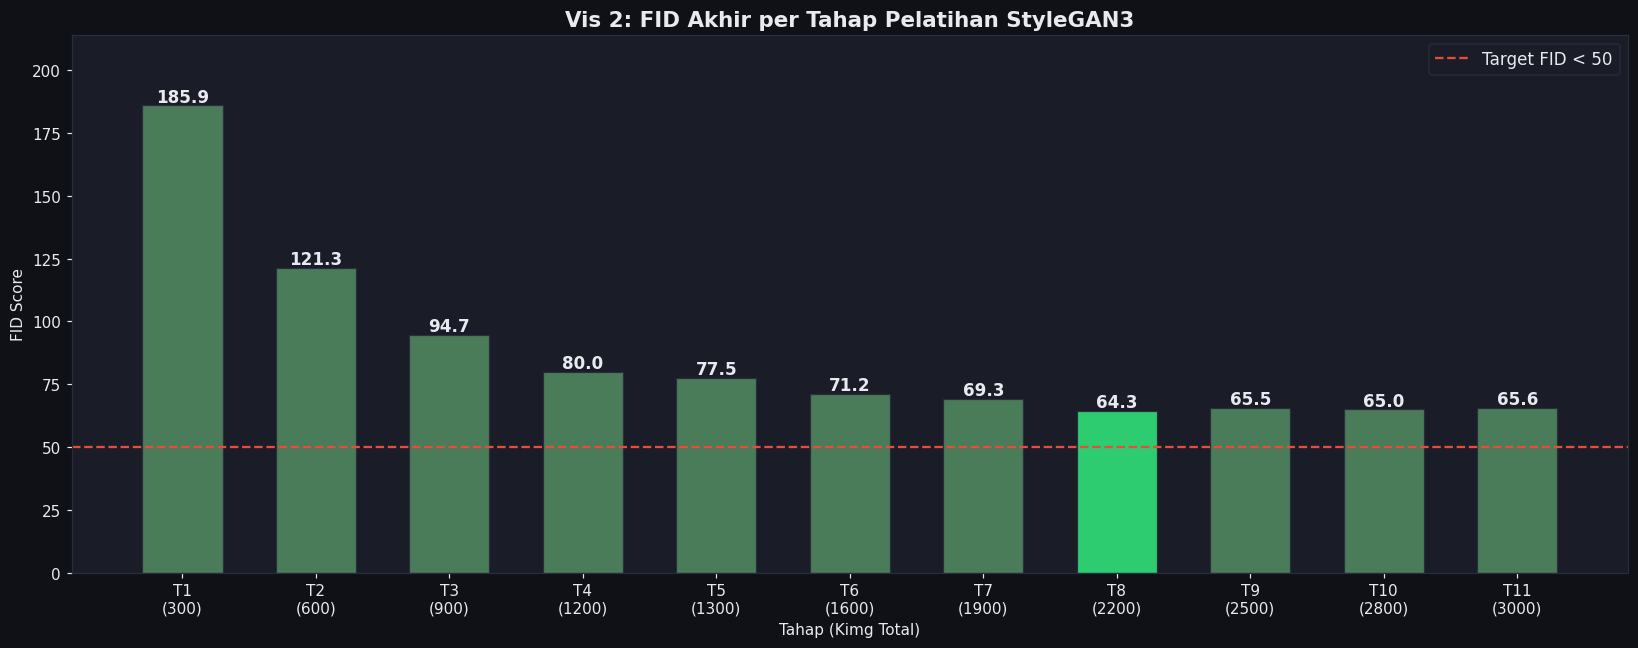

In [4]:
# VISUALISASI 2: FID Akhir per Tahap
tambahan = {1:300,2:300,3:300,4:300,5:100,6:300,7:300,8:300,9:300,10:300,11:200}
tahap_fid = []
for t in sorted(kimg_start.keys()):
    sub = dff[dff.Tahap==t]
    if len(sub):
        tahap_fid.append((f'T{t}\n({kimg_start[t]+tambahan.get(t,300)})', sub.FID.iloc[-1]))
labels, values = [x[0] for x in tahap_fid], [x[1] for x in tahap_fid]
fig, ax = plt.subplots(figsize=(15,6))
bars = ax.bar(labels, values,
              color=['#2ecc71' if v==min(values) else '#4a7c59' for v in values],
              edgecolor=GRID, linewidth=0.8, width=0.6)
for bar, val in zip(bars, values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            f'{val:.1f}', ha='center', fontsize=11, fontweight='bold')
ax.axhline(50, color='#e74c3c', lw=1.5, linestyle='--', label='Target FID < 50')
ax.set_title('Vis 2: FID Akhir per Tahap Pelatihan StyleGAN3', fontsize=14, fontweight='bold')
ax.set_xlabel('Tahap (Kimg Total)'); ax.set_ylabel('FID Score')
ax.legend(fontsize=11); ax.set_ylim(0, max(values)*1.15)
plt.tight_layout(); plt.show()


---
## 🧬 Visualisasi 3 — Intensitas Augmentasi ADA

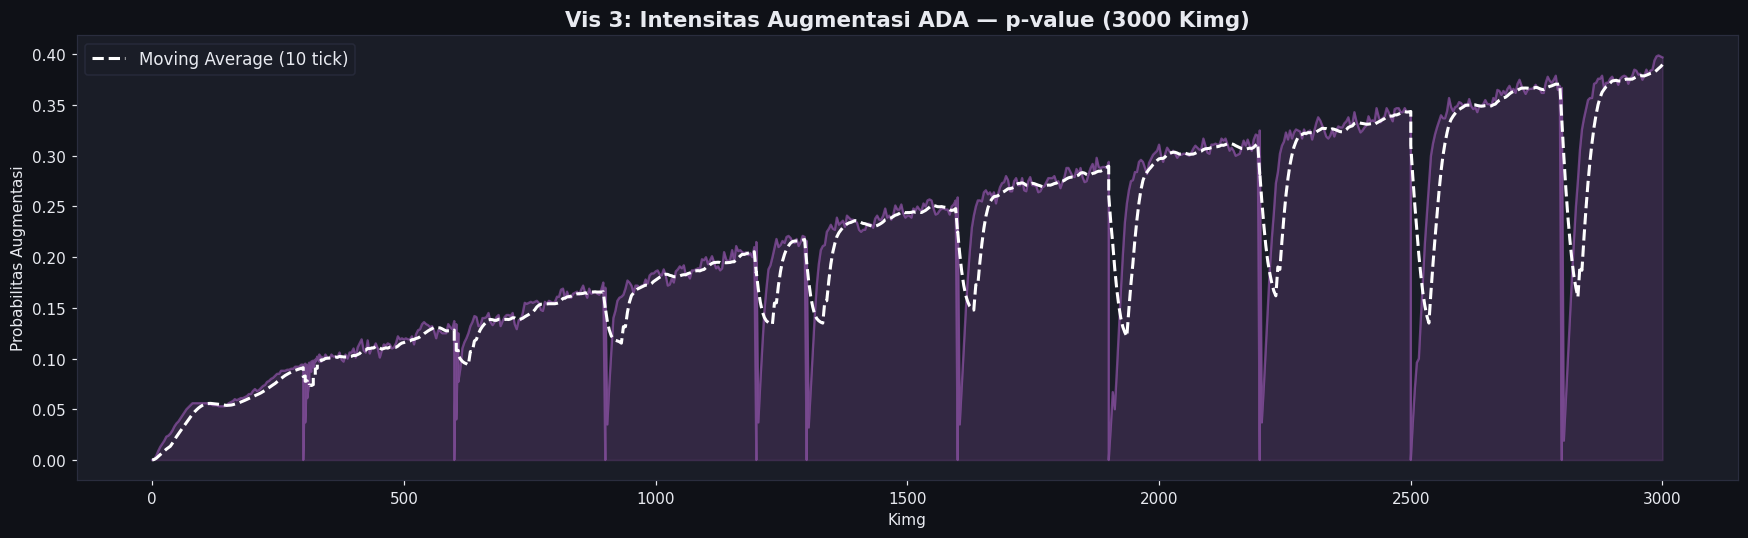

ADA p-value akhir: 0.397


In [5]:
# VISUALISASI 3: Intensitas Augmentasi ADA
fig, ax = plt.subplots(figsize=(16,5))
ax.fill_between(df.Kimg, df.Aug, alpha=0.2, color=PALETTE['aug'])
ax.plot(df.Kimg, df.Aug, color=PALETTE['aug'], lw=1.5, alpha=0.6)
ax.plot(df.Kimg, df.Aug.rolling(10,min_periods=1).mean(),
        color='white', lw=2, linestyle='--', label='Moving Average (10 tick)')
ax.set_title('Vis 3: Intensitas Augmentasi ADA — p-value (3000 Kimg)', fontsize=14, fontweight='bold')
ax.set_xlabel('Kimg'); ax.set_ylabel('Probabilitas Augmentasi')
ax.legend(fontsize=11)
plt.tight_layout(); plt.show()
print(f'ADA p-value akhir: {df.Aug.iloc[-1]:.3f}')


---
## ⚡ Visualisasi 4 — Efisiensi Komputasi (Detik/Kimg)

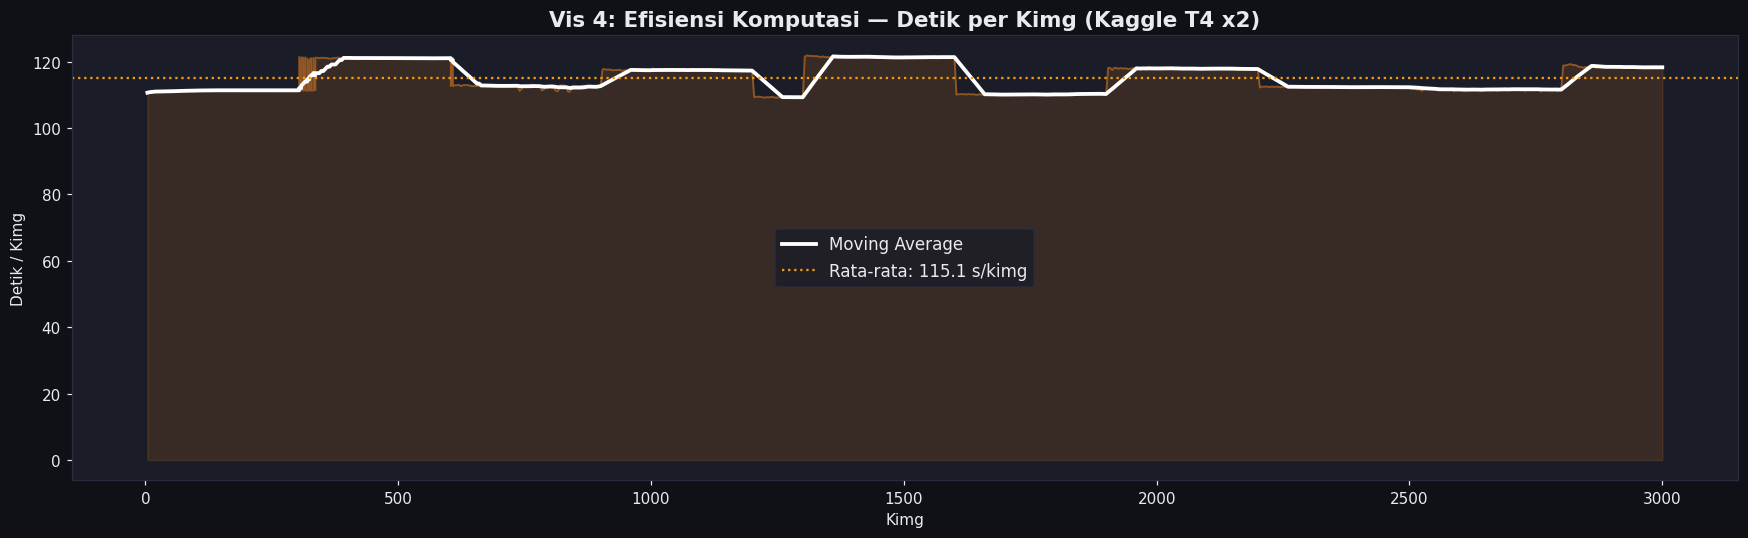

Estimasi total waktu 3000 Kimg: 95.9 jam


In [6]:
# VISUALISASI 4: Efisiensi Komputasi
df_s = df[df.Sec.between(50, 500)]
fig, ax = plt.subplots(figsize=(16,5))
ax.fill_between(df_s.Kimg, df_s.Sec, alpha=0.15, color=PALETTE['speed'])
ax.plot(df_s.Kimg, df_s.Sec, color=PALETTE['speed'], lw=1.2, alpha=0.5)
ax.plot(df_s.Kimg, df_s.Sec.rolling(15,min_periods=1).mean(),
        color='white', lw=2.5, label='Moving Average')
ax.axhline(df_s.Sec.mean(), color=PALETTE['accent'], lw=1.5, linestyle=':',
           label=f'Rata-rata: {df_s.Sec.mean():.1f} s/kimg')
ax.set_title('Vis 4: Efisiensi Komputasi — Detik per Kimg (Kaggle T4 x2)', fontsize=14, fontweight='bold')
ax.set_xlabel('Kimg'); ax.set_ylabel('Detik / Kimg')
ax.legend(fontsize=11)
plt.tight_layout(); plt.show()
print(f'Estimasi total waktu 3000 Kimg: {df_s.Sec.mean()*3000/3600:.1f} jam')


---
## 💾 Visualisasi 5 — Utilisasi Memori Hardware

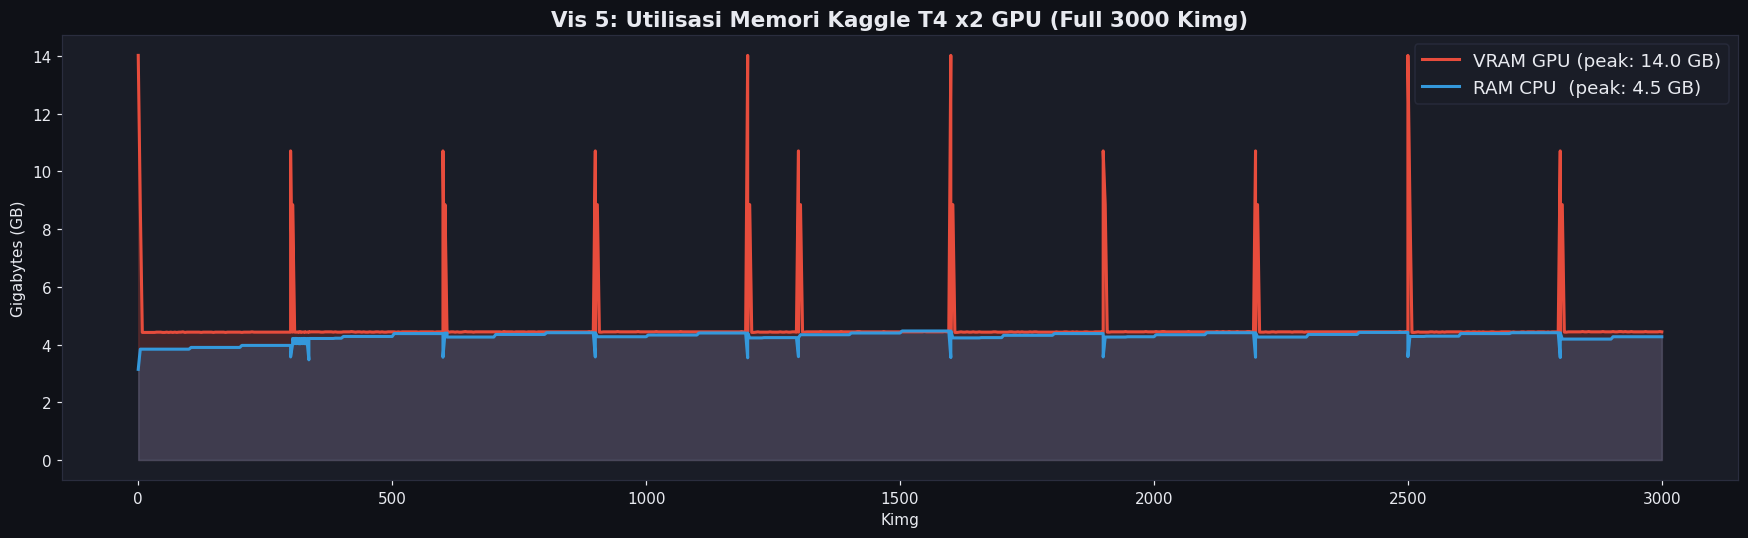

Peak VRAM: 14.02 GB | Peak RAM: 4.47 GB


In [7]:
# VISUALISASI 5: Utilisasi Memori Hardware
fig, ax = plt.subplots(figsize=(16,5))
ax.fill_between(df.Kimg, df.GPU, alpha=0.2, color=PALETTE['vram'])
ax.plot(df.Kimg, df.GPU, color=PALETTE['vram'], lw=2, label=f'VRAM GPU (peak: {df.GPU.max():.1f} GB)')
ax.fill_between(df.Kimg, df.CPU, alpha=0.2, color=PALETTE['ram'])
ax.plot(df.Kimg, df.CPU, color=PALETTE['ram'],  lw=2, label=f'RAM CPU  (peak: {df.CPU.max():.1f} GB)')
ax.set_title('Vis 5: Utilisasi Memori Kaggle T4 x2 GPU (Full 3000 Kimg)', fontsize=14, fontweight='bold')
ax.set_xlabel('Kimg'); ax.set_ylabel('Gigabytes (GB)')
ax.legend(fontsize=12)
plt.tight_layout(); plt.show()
print(f'Peak VRAM: {df.GPU.max():.2f} GB | Peak RAM: {df.CPU.max():.2f} GB')


---
## 🖼️  Visualisasi 6 — Komparasi Gambar Awal vs Akhir

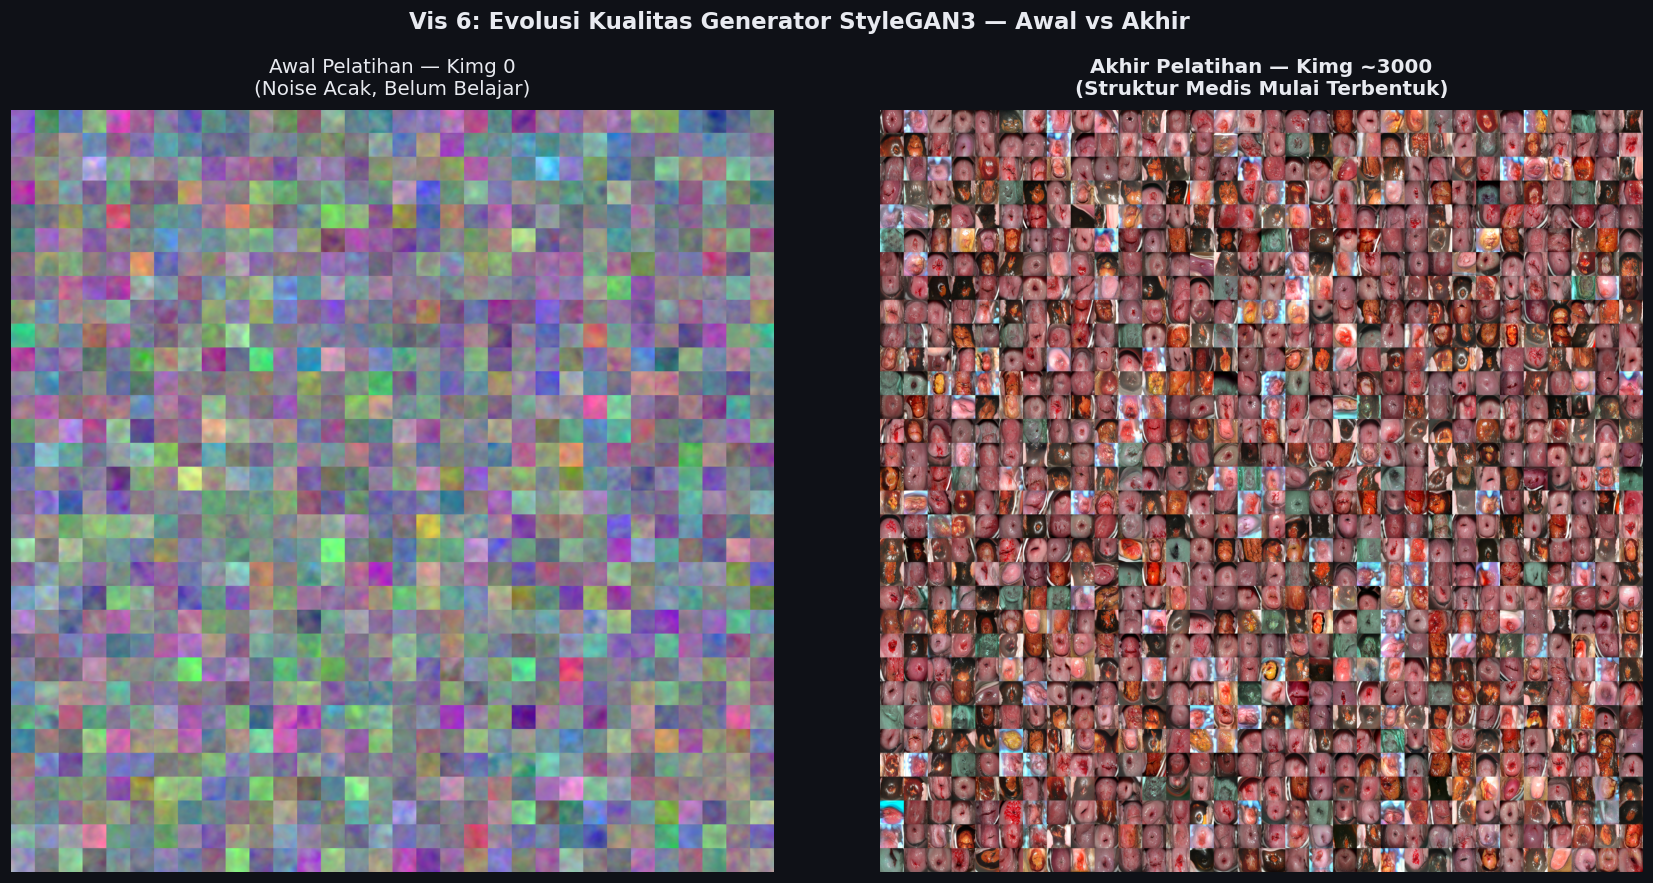

In [8]:
# VISUALISASI 6: Komparasi Gambar Awal vs Akhir
all_fakes = []
for d in sorted(glob.glob(os.path.join(BASE,'tahap *'))):
    all_fakes.extend(sorted(glob.glob(os.path.join(d,'fakes*.png'))))

if len(all_fakes) >= 2:
    fig = plt.figure(figsize=(20,9))
    gs  = gridspec.GridSpec(1,2,figure=fig,wspace=0.04)
    for idx,(path,title) in enumerate([
        (all_fakes[0],  'Awal Pelatihan — Kimg 0\n(Noise Acak, Belum Belajar)'),
        (all_fakes[-1], 'Akhir Pelatihan — Kimg ~3000\n(Struktur Medis Mulai Terbentuk)')
    ]):
        ax = fig.add_subplot(gs[idx])
        ax.imshow(mpimg.imread(path)); ax.axis('off')
        ax.set_title(title, fontsize=13,
                     fontweight='bold' if idx else 'normal', pad=10)
    fig.suptitle('Vis 6: Evolusi Kualitas Generator StyleGAN3 — Awal vs Akhir',
                 fontsize=15, fontweight='bold')
    plt.tight_layout(); plt.show()


---
## 🔥 Visualisasi 7 — Heatmap FID per Tahap x Checkpoint

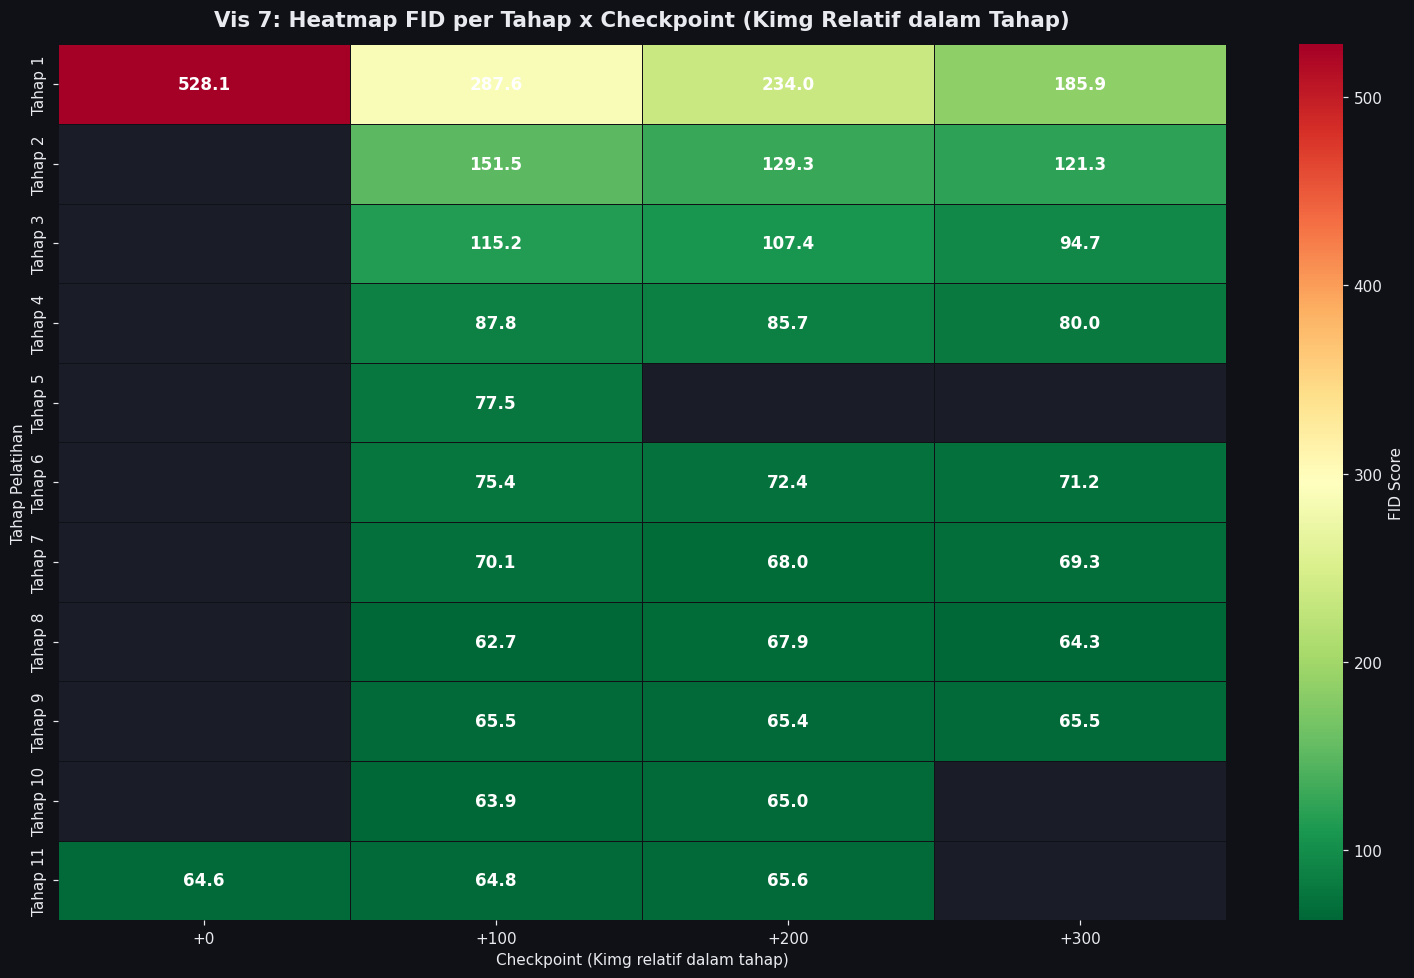

In [9]:
# VISUALISASI 7: Heatmap FID per Tahap x Checkpoint
heat_data = {}
for t in sorted(kimg_start.keys()):
    for _,row in dff[dff.Tahap==t].iterrows():
        heat_data[(t, int(row.Kimg-kimg_start[t]))] = row.FID

checkpoints = sorted(set(c for (t,c) in heat_data))
tahaps = sorted(kimg_start.keys())
matrix = np.full((len(tahaps),len(checkpoints)), np.nan)
for i,t in enumerate(tahaps):
    for j,c in enumerate(checkpoints):
        if (t,c) in heat_data: matrix[i,j] = heat_data[(t,c)]

fig, ax = plt.subplots(figsize=(14,9))
sns.heatmap(matrix, annot=True, fmt='.1f', mask=np.isnan(matrix),
            xticklabels=[f'+{c}' for c in checkpoints],
            yticklabels=[f'Tahap {t}' for t in tahaps],
            cmap='RdYlGn_r', linewidths=0.5, linecolor=BG,
            annot_kws={'size':11,'fontweight':'bold','color':'white'},
            cbar_kws={'label':'FID Score'}, ax=ax)
ax.set_title('Vis 7: Heatmap FID per Tahap x Checkpoint (Kimg Relatif dalam Tahap)',
             fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Checkpoint (Kimg relatif dalam tahap)')
ax.set_ylabel('Tahap Pelatihan')
plt.tight_layout(); plt.show()


---
## 🗂️  Visualisasi 8 — Summary Dashboard

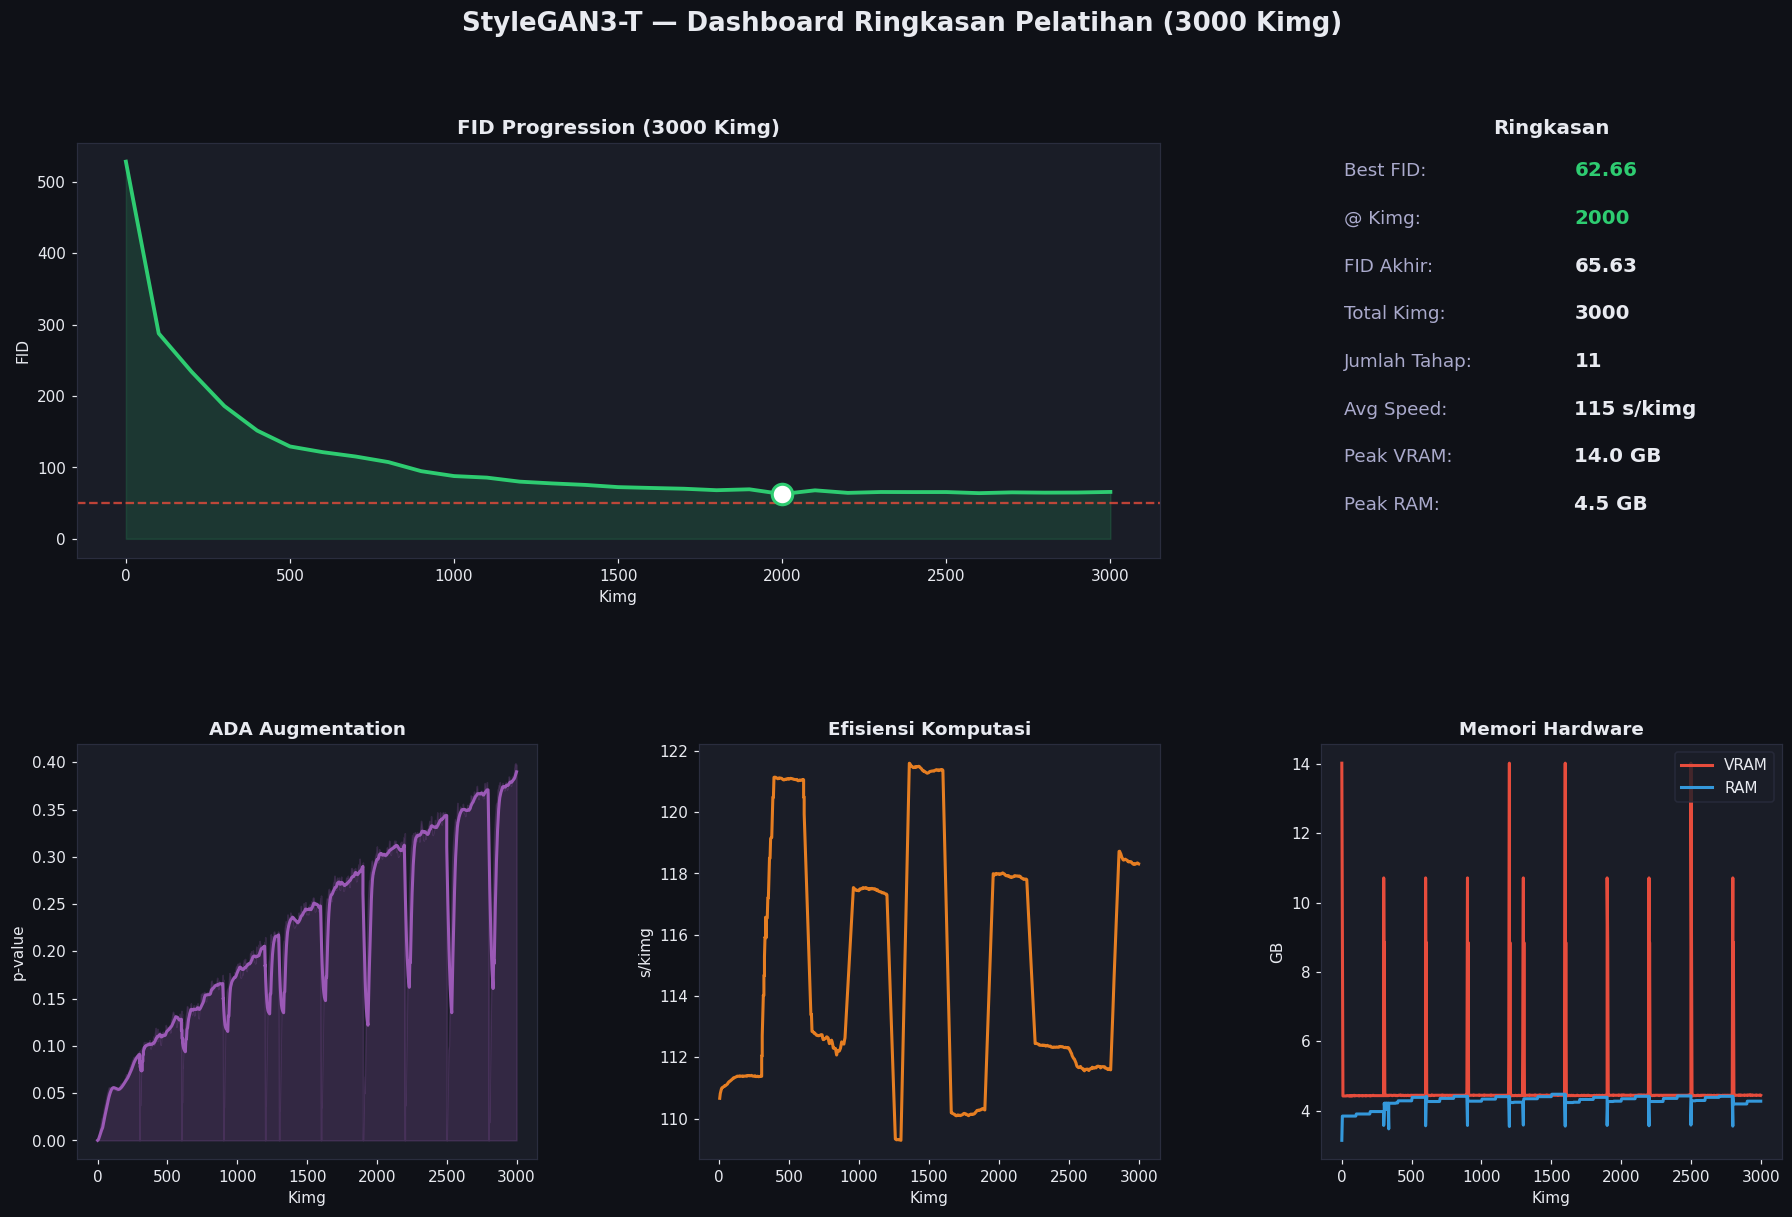

In [10]:
# VISUALISASI 8: Summary Dashboard
fig = plt.figure(figsize=(20,12))
gs  = gridspec.GridSpec(2,3,figure=fig,hspace=0.45,wspace=0.35)

ax1 = fig.add_subplot(gs[0,:2])
ax1.fill_between(dff.Kimg,dff.FID,alpha=0.15,color=PALETTE['fid'])
ax1.plot(dff.Kimg,dff.FID,color=PALETTE['fid'],lw=2.5)
ax1.scatter([bk],[bf],s=180,color='white',zorder=5,edgecolors=PALETTE['fid'],lw=2)
ax1.axhline(50,color='#e74c3c',lw=1.5,linestyle='--',alpha=0.8)
ax1.set_title('FID Progression (3000 Kimg)',fontsize=13,fontweight='bold')
ax1.set_xlabel('Kimg'); ax1.set_ylabel('FID')

ax2 = fig.add_subplot(gs[0,2]); ax2.axis('off')
for i,(k,v) in enumerate([('Best FID',f'{bf:.2f}'),('@ Kimg',f'{bk:.0f}'),
    ('FID Akhir',f'{dff.FID.iloc[-1]:.2f}'),('Total Kimg',f'{dff.Kimg.max():.0f}'),
    ('Jumlah Tahap','11'),('Avg Speed',f'{df[df.Sec.between(50,500)].Sec.mean():.0f} s/kimg'),
    ('Peak VRAM',f'{df.GPU.max():.1f} GB'),('Peak RAM',f'{df.CPU.max():.1f} GB')]):
    ax2.text(0.05,0.92-i*0.115,k+':',color='#aaaacc',fontsize=12,transform=ax2.transAxes)
    ax2.text(0.55,0.92-i*0.115,v,
             color=PALETTE['fid'] if i<2 else TXT,
             fontsize=13,fontweight='bold',transform=ax2.transAxes)
ax2.set_title('Ringkasan',fontsize=13,fontweight='bold')

ax3 = fig.add_subplot(gs[1,0])
ax3.fill_between(df.Kimg,df.Aug,alpha=0.2,color=PALETTE['aug'])
ax3.plot(df.Kimg,df.Aug.rolling(10,min_periods=1).mean(),color=PALETTE['aug'],lw=2)
ax3.set_title('ADA Augmentation',fontsize=12,fontweight='bold')
ax3.set_xlabel('Kimg'); ax3.set_ylabel('p-value')

df_s = df[df.Sec.between(50,500)]
ax4 = fig.add_subplot(gs[1,1])
ax4.plot(df_s.Kimg,df_s.Sec.rolling(15,min_periods=1).mean(),color=PALETTE['speed'],lw=2)
ax4.set_title('Efisiensi Komputasi',fontsize=12,fontweight='bold')
ax4.set_xlabel('Kimg'); ax4.set_ylabel('s/kimg')

ax5 = fig.add_subplot(gs[1,2])
ax5.plot(df.Kimg,df.GPU,color=PALETTE['vram'],lw=2,label='VRAM')
ax5.plot(df.Kimg,df.CPU,color=PALETTE['ram'], lw=2,label='RAM')
ax5.legend(fontsize=10)
ax5.set_title('Memori Hardware',fontsize=12,fontweight='bold')
ax5.set_xlabel('Kimg'); ax5.set_ylabel('GB')

fig.suptitle('StyleGAN3-T — Dashboard Ringkasan Pelatihan (3000 Kimg)',
             fontsize=17,fontweight='bold')
plt.tight_layout(); plt.show()


---
## Ringkasan Akhir Pelatihan

In [11]:
print('='*65)
print('  RINGKASAN PELATIHAN STYLEGAN3-T — SKRIPSI')
print('='*65)
print(f'  Arsitektur       : StyleGAN3-T (Translation Equivariant)')
print(f'  Hardware         : Kaggle T4 x2 GPU')
print(f'  Dataset          : Serviks 666 gambar, 128x128 px')
print(f'  Total Kimg       : {dff.Kimg.max():.0f}')
print(f'  Jumlah Tahap     : 11')
print(f'  FID Awal         : {dff.FID.iloc[0]:.2f}')
print(f'  FID Terbaik      : {dff.FID.min():.2f} @ Kimg {dff.loc[dff.FID.idxmin(),"Kimg"]:.0f}')
print(f'  FID Akhir        : {dff.FID.iloc[-1]:.2f}')
print(f'  Target FID < 50  : BELUM TERCAPAI')
print(f'  Peak VRAM        : {df.GPU.max():.2f} GB')
print(f'  Peak RAM         : {df.CPU.max():.2f} GB')
print(f'  Avg Speed        : {df[df.Sec.between(50,500)].Sec.mean():.1f} s/kimg')
print('='*65)


  RINGKASAN PELATIHAN STYLEGAN3-T — SKRIPSI
  Arsitektur       : StyleGAN3-T (Translation Equivariant)
  Hardware         : Kaggle T4 x2 GPU
  Dataset          : Serviks 666 gambar, 128x128 px
  Total Kimg       : 3000
  Jumlah Tahap     : 11
  FID Awal         : 528.09
  FID Terbaik      : 62.66 @ Kimg 2000
  FID Akhir        : 65.63
  Target FID < 50  : BELUM TERCAPAI
  Peak VRAM        : 14.02 GB
  Peak RAM         : 4.47 GB
  Avg Speed        : 115.1 s/kimg
